# 01 · Momentum 12-1 sobre sectores del S&P 500

**Pregunta:** ¿comprar cada mes los 3 sectores que más han subido en los últimos 12 meses (saltando el último) bate a tener los 9 sectores a partes iguales?

**Respuesta corta:** no de forma apreciable. Con 5 pb de costes el resultado es un empate (Sharpe 0,64 en ambos), y con 20 pb el momentum queda por detrás. El detalle y los motivos están al final.

Reglas de este notebook:
- Solo importa de `backtester` y presenta resultados; la lógica está en `src/` con sus tests.
- Los parámetros (12-1, top 3, rebalanceo mensual) se fijaron **antes** de ver los resultados. No se ha probado ninguna otra combinación.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from backtester import ProportionalCosts, run_backtest
from backtester.data import load_prices, quality_report
from backtester.report import compare, plot_result
from backtester.strategies import CrossSectionalMomentum
from backtester.strategy import BuyAndHold, EqualWeight

SECTOR_ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
START, END = "2005-01-01", "2026-10-31"  # fecha final fija: números reproducibles
IMG_DIR = Path("../docs/img")

## 1. Datos

Cierres ajustados (dividendos y splits) de Yahoo Finance para los 9 ETFs sectoriales SPDR que existen desde 1998.

In [2]:
prices = load_prices(SECTOR_ETFS, start=START, end=END)
print(f"{prices.shape[0]} sesiones, de {prices.index[0].date()} a {prices.index[-1].date()}")
quality_report(prices)

5492 sesiones, de 2005-01-03 a 2026-10-30


,Primera fecha,Última fecha,Observaciones,NaN internos,Precios no positivos,Mayor |rend. diario|,Mayor hueco (días)
XLB,2005-01-03,2026-10-30,5492,0,0,0.140576,5
XLE,2005-01-03,2026-10-30,5492,0,0,0.201412,5
XLF,2005-01-03,2026-10-30,5492,0,0,0.166667,5
XLI,2005-01-03,2026-10-30,5492,0,0,0.126512,5
XLK,2005-01-03,2026-10-30,5492,0,0,0.138983,5
XLP,2005-01-03,2026-10-30,5492,0,0,0.093956,5
XLU,2005-01-03,2026-10-30,5492,0,0,0.127934,5
XLV,2005-01-03,2026-10-30,5492,0,0,0.120547,5
XLY,2005-01-03,2026-10-30,5492,0,0,0.126686,5


**Qué sale de la revisión**

- Los 9 ETFs tienen las mismas 5.492 sesiones: no hay fechas de inicio distintas ni NaN internos.
- El mayor hueco entre sesiones es de 5 días naturales y ocurre dos veces, ambas por cierres reales del mercado: el 2 de enero de 2007 (funeral de Gerald Ford) y el huracán Sandy en octubre de 2012.
- Los mayores movimientos diarios (entre el 9 % y el 20 %) son plausibles para sectores en crisis, no errores de datos.
- **Un problema que sí apareció:** en la primera descarga Yahoo falló con XLB y devolvió la columna entera vacía, sin dar error. El backtest se ejecutó igualmente con 8 sectores y la caché rota se habría reutilizado siempre. Ahora `load_prices` lanza un error si falta algún ticker.

**Limitaciones del universo**

- Faltan los dos sectores más nuevos: XLRE (inmobiliario, 2015) y XLC (comunicaciones, 2018). Se dejan fuera para tener un universo constante. Al crearse, sus empresas salieron de XLF, XLK y XLY, así que la composición de esos tres cambió por el camino.
- Los cierres ajustados de Yahoo se recalculan con cada dividendo, así que los números pueden variar ligeramente si se vuelve a descargar más adelante.

## 2. Backtest

- **Momentum 12-1:** cada fin de mes, los 3 sectores con mayor rendimiento entre *t-252* y *t-21* sesiones, a partes iguales. Costes de 5 pb por unidad de turnover.
- **Equiponderado:** los 9 sectores al 11,1 %, reequilibrados también cada fin de mes y con los mismos 5 pb.
- **Buy & hold** (solo como referencia en la tabla de métricas): comprar los 9 sectores a partes iguales al principio y no volver a operar.

Entre rebalanceos el motor no opera: los pesos derivan con los precios, y volver al objetivo cuenta como turnover y paga costes.

Un aviso sobre la comparación: el momentum necesita un año de historia, así que durante 2005 está en efectivo. Para no mezclar "momentum" con "un año sin invertir", todas las series se recortan al primer día en que el momentum tiene posición.

In [3]:
def run_momentum(bps: float):
    return run_backtest(
        prices, CrossSectionalMomentum(top_n=3), ProportionalCosts(bps=bps), rebalance="ME"
    )


start = run_momentum(5).first_active
momentum = run_momentum(5).since(start)
benchmark = run_backtest(
    prices, EqualWeight(), ProportionalCosts(bps=5), rebalance="ME"
).since(start)
# Referencia: comprar los 9 sectores a partes iguales la víspera de `start` y no operar más.
entry = prices.index[prices.index.get_loc(start) - 1]
buy_hold = run_backtest(prices.loc[entry:], BuyAndHold(), ProportionalCosts(bps=5)).since(start)
print(f"Periodo comparado: {start.date()} a {prices.index[-1].date()}")

Periodo comparado: 2006-02-01 a 2026-10-30


## 3. Equity y drawdown

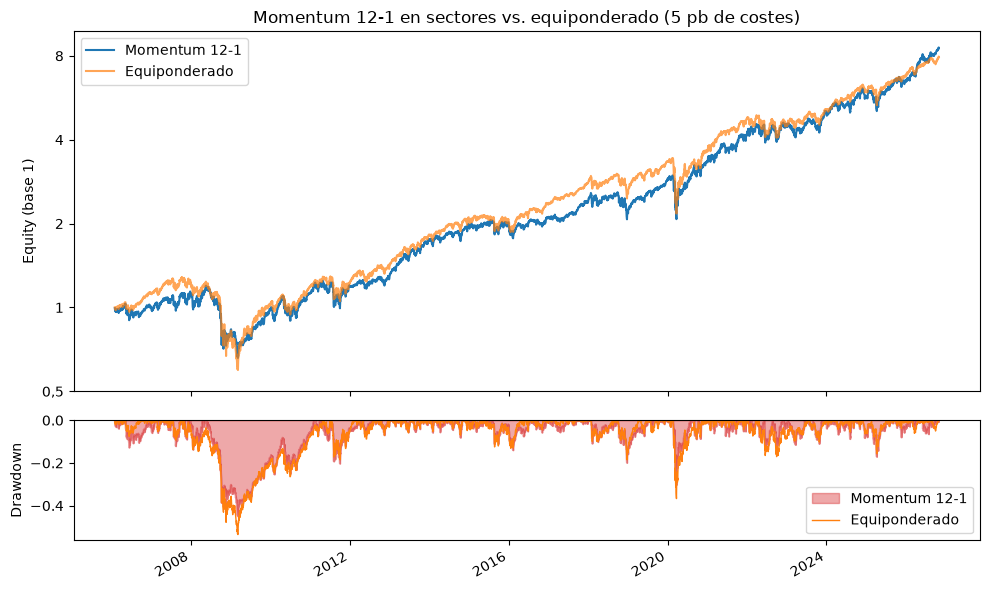

In [4]:
fig = plot_result(
    momentum,
    benchmark,
    title="Momentum 12-1 en sectores vs. equiponderado (5 pb de costes)",
    labels=("Momentum 12-1", "Equiponderado"),
)
ax_equity = fig.axes[0]
ax_equity.set_yscale("log")  # 20 años de crecimiento compuesto: en escala lineal 2008 no se ve
ax_equity.set_yticks([0.5, 1, 2, 4, 8], labels=["0,5", "1", "2", "4", "8"])
ax_equity.minorticks_off()
fig.tight_layout()
IMG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG_DIR / "momentum_sectores.png", dpi=150)
plt.show()

## 4. Métricas

In [5]:
metrics = compare(
    {"Momentum 12-1": momentum, "Equiponderado": benchmark, "Buy & hold": buy_hold}
)
metrics.round(3)

,Momentum 12-1,Equiponderado,Buy & hold
CAGR,0.109,0.105,0.105
Volatilidad anual,0.188,0.183,0.180
Sharpe,0.645,0.637,0.648
Sortino,0.907,0.892,0.908
Max drawdown,-0.450,-0.535,-0.517
Calmar,0.242,0.196,0.204
Turnover anual,5.250,0.294,0.048
Costes anuales,0.003,0.000,0.000


## 5. Sensibilidad a los costes

El mismo momentum con 0, 5 y 20 pb por unidad de turnover. El benchmark solo mueve 0,3 veces la cartera al año para volver a partes iguales, así que sus costes son despreciables.

In [6]:
by_cost = {f"Momentum {bps} pb": run_momentum(bps).since(start) for bps in (0, 5, 20)}
compare({**by_cost, "Equiponderado": benchmark}).round(3)

,Momentum 0 pb,Momentum 5 pb,Momentum 20 pb,Equiponderado
CAGR,0.112,0.109,0.100,0.105
Volatilidad anual,0.188,0.188,0.188,0.183
Sharpe,0.659,0.645,0.603,0.637
Sortino,0.927,0.907,0.847,0.892
Max drawdown,-0.449,-0.450,-0.452,-0.535
Calmar,0.249,0.242,0.222,0.196
Turnover anual,5.250,5.250,5.250,0.294
Costes anuales,0.000,0.003,0.010,0.000


## 6. Año a año

Rendimiento anual de cada cartera y diferencia (momentum menos equiponderado). 2006 empieza en febrero y 2026 acaba en octubre.

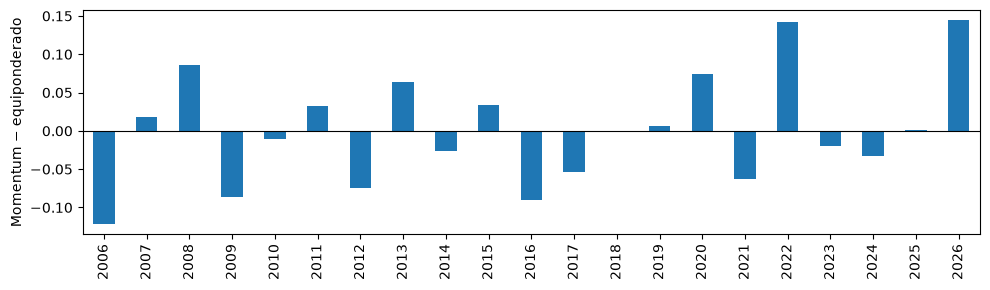

El momentum gana 10 de 21 años.
Correlación diaria con el benchmark: 0.90


,Momentum 12-1,Equiponderado,Diferencia
Date,,,
2006,0.004,0.125,-0.122
2007,0.113,0.095,0.018
2008,-0.269,-0.355,0.085
2009,0.195,0.281,-0.086
2010,0.150,0.161,-0.010
2011,0.064,0.031,0.033
2012,0.073,0.147,-0.075
2013,0.372,0.308,0.064
2014,0.107,0.133,-0.026


In [7]:
def yearly(result):
    return (1 + result.returns).groupby(result.returns.index.year).prod() - 1


by_year = pd.DataFrame({"Momentum 12-1": yearly(momentum), "Equiponderado": yearly(benchmark)})
by_year["Diferencia"] = by_year["Momentum 12-1"] - by_year["Equiponderado"]

ax = by_year["Diferencia"].plot(kind="bar", figsize=(10, 3), color="tab:blue")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Momentum − equiponderado")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

wins = int((by_year["Diferencia"] > 0).sum())
corr = momentum.returns.corr(benchmark.returns)
print(f"El momentum gana {wins} de {len(by_year)} años.")
print(f"Correlación diaria con el benchmark: {corr:.2f}")
by_year.round(3)

## 7. Interpretación

**El momentum sectorial no bate al equiponderado de forma apreciable.**

| | Momentum 12-1 (5 pb) | Equiponderado | Buy & hold |
|---|---|---|---|
| CAGR | 10,9 % | 10,5 % | 10,5 % |
| Sharpe | 0,64 | 0,64 | 0,65 |
| Max drawdown | −45,0 % | −53,5 % | −51,7 % |

- **Rentabilidad:** 0,4 puntos más al año, con algo más de volatilidad. El Sharpe es idéntico al segundo decimal.
- **Costes:** la estrategia rota la cartera unas 5 veces al año. Sin costes saca 0,7 puntos al benchmark; con 5 pb, 0,4; con 20 pb queda 0,5 por debajo. La ventaja bruta es del mismo tamaño que unos costes realistas.
- **Año a año:** gana 10 de 21 años, es decir, a cara o cruz. La ventaja se concentra en tres años (2026, 2022 y 2008); los otros 18, en conjunto, restan.
- **Drawdown:** la única diferencia visible es la caída máxima, 8,5 puntos menor. Pero es un solo episodio (2008), y una observación no demuestra que la estrategia proteja en las caídas.

- **Buy & hold:** no reequilibrar nunca da prácticamente lo mismo que reequilibrar cada mes (10,5 % en ambos casos), aunque la cartera acaba muy lejos de las partes iguales: XLK pesa un 31 % al final. El momentum tampoco lo bate con claridad.
- **Efecto de modelar la deriva de pesos:** antes el motor reequilibraba cada día sin coste. Al corregirlo, las cifras bajan un poco en las dos carteras (momentum de 11,0 % a 10,9 % de CAGR; equiponderado de 10,7 % a 10,5 %; Sharpe de 0,65 a 0,64 en ambos) y la conclusión no cambia.

Con 21 años y una diferencia de este tamaño no puedo afirmar que la ventaja sea distinta de cero. La fase 3 del proyecto (bootstrap de bloques e intervalos de confianza del Sharpe) sirve para cuantificarlo.

### Por qué puede pasar

1. **Universo muy pequeño y muy correlacionado.** Con 9 sectores, el "top 3" es un tercio del mercado. La cartera resultante tiene una correlación de 0,90 con el benchmark: es sobre todo beta de mercado con una pequeña apuesta sectorial encima. El momentum de la literatura (Jegadeesh y Titman, 1993) se mide con cientos de acciones y con cartera larga-corta.
2. **Solo posiciones largas.** La prima de momentum clásica es ganadores menos perdedores. Aquí solo se compra a los ganadores, así que la parte corta de la prima no se captura.
3. **Los giros de mercado.** El momentum llega tarde a los rebotes: en 2009 pierde casi 9 puntos frente al benchmark, y vuelve a quedarse atrás en 2012 y 2016. Gana cuando la tendencia dura (2008, 2020, 2022).
4. **El benchmark es exigente.** Reequilibrar a partes iguales vende lo que sube y compra lo que baja, justo lo contrario del momentum.
5. **Un solo camino histórico.** Hay 21 años y una única secuencia de crisis. El resultado depende de unos pocos episodios.

### Qué no se puede concluir

- Que el momentum "no funciona": solo que esta versión, en este universo y con estos costes, no añade valor claro sobre el equiponderado.
- Que la menor caída máxima sea una propiedad de la estrategia.

### Siguientes pasos

- Probar la versión larga-corta y medir la significación estadística (fase 3).